# NicheJEPA Tutorial xhs1000-skin

- Creator: Sebastian Birk (sb75@sanger.ac.uk) Mohammad Vali Sanian (mohammad.sanian@helsinki.fi)
- Date of Creation: 30.06.2025
- Date of Last Modification: 08.07.2025 (by Mohammad Vali Sanian mohammad.sanian@helsinki.fi)

## 1. Setup

### 1.1 Load Libraries 

In [40]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
sys.path.append("../../utils")

In [ ]:
import logging
import os
import warnings
from typing import List, Tuple
import torch
from sklearn.metrics import silhouette_score
import gseapy as gp

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from datasets import load_from_disk
from matplotlib.colors import Normalize
import squidpy as sq
from tqdm import tqdm
from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_gene_embed,
                       get_average_gene_embed,
                       get_spatial_score,
                       get_emd_distance )
from nichejepa.utils.evaluation import (get_top_gene_score,
                                        get_top_gene_pairs
                                        )
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

In [ ]:
## This function takes a list of cell_ids and returns the corresponding dataset object.
def subset_by_cell_ids(dataset, cell_id_list):
    cell_id_set = set(cell_id_list)
    cell_ids = dataset['cell_id']
    indices = [i for i, cid in tqdm(enumerate(cell_ids), total=len(cell_ids), desc="Finding matching indices") if cid in cell_id_set]
    return dataset.select(indices)


### 1.2 Configure Paths

In [5]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055'

### 1.3 Define Config

In [6]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [7]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [8]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [9]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [10]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'
sc.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)


In [ ]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhs1000-skin

In [2]:
dataset_name = 'xhs1000-39b_1p'
cell_type_key = 'niche_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch19.h5ad'

#### 2.1.1 Load Data

In [3]:
adata = sc.read_h5ad(file_path)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


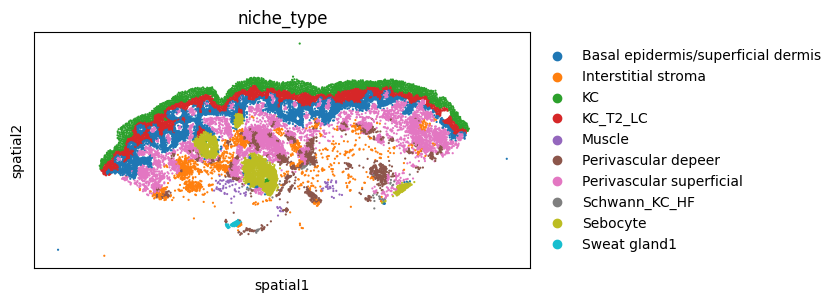

In [4]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

#### 2.1.2 Harmonize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [15]:
adata = harmonize_adata(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


#### 2.1.3 Tokenize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [16]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/mv10/nemo_v6/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...


Map (num_proc=4):   0%|          | 0/17384 [00:00<?, ? examples/s]

#### 2.1.4 Save Tokenize Data

In [17]:
num_shards = 32
save_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'

In [18]:
!mkdir save_dataset_path

In [19]:
dataset.save_to_disk(
            save_dataset_path,
            num_shards=num_shards)

Saving the dataset (0/32 shards):   0%|          | 0/17384 [00:00<?, ? examples/s]

#### 2.1.5 Load Tokenize Data

In [12]:
load_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'
dataset = load_from_disk(load_dataset_path)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [16]:
temp = dataset['cell_id']

In [19]:
len(temp)

321911

#### 2.1.6 Embed Data

In [23]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

In [24]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
136it [02:35,  1.14s/it]


In [25]:
adata.obsm['cell_emb'] = output_embed['cell_emb']
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


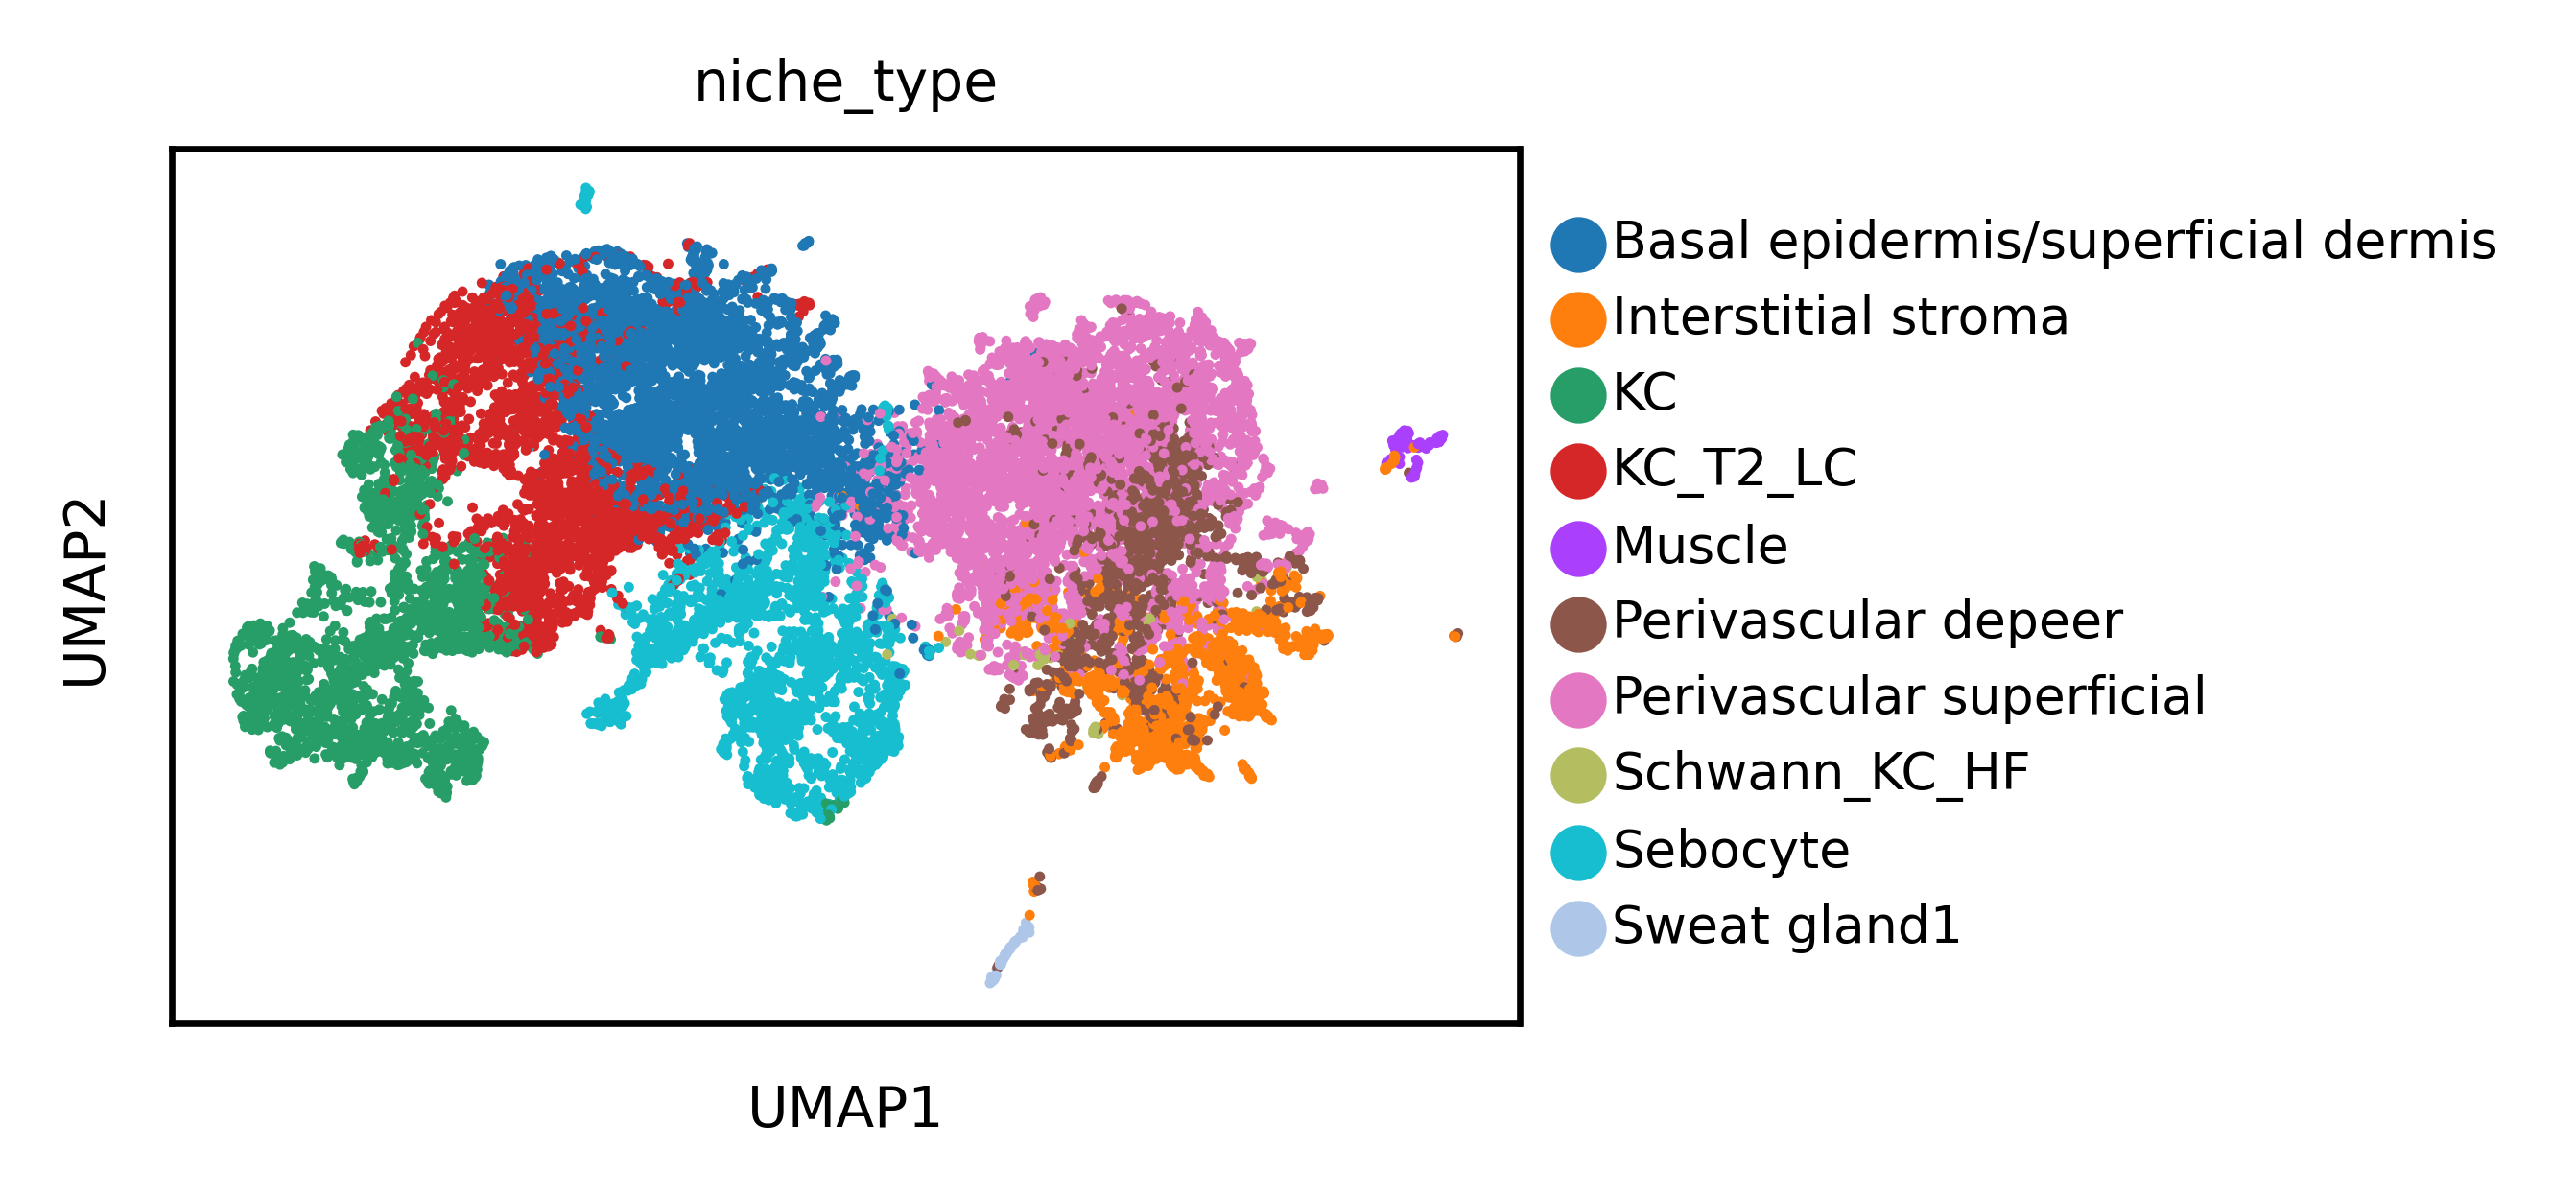

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


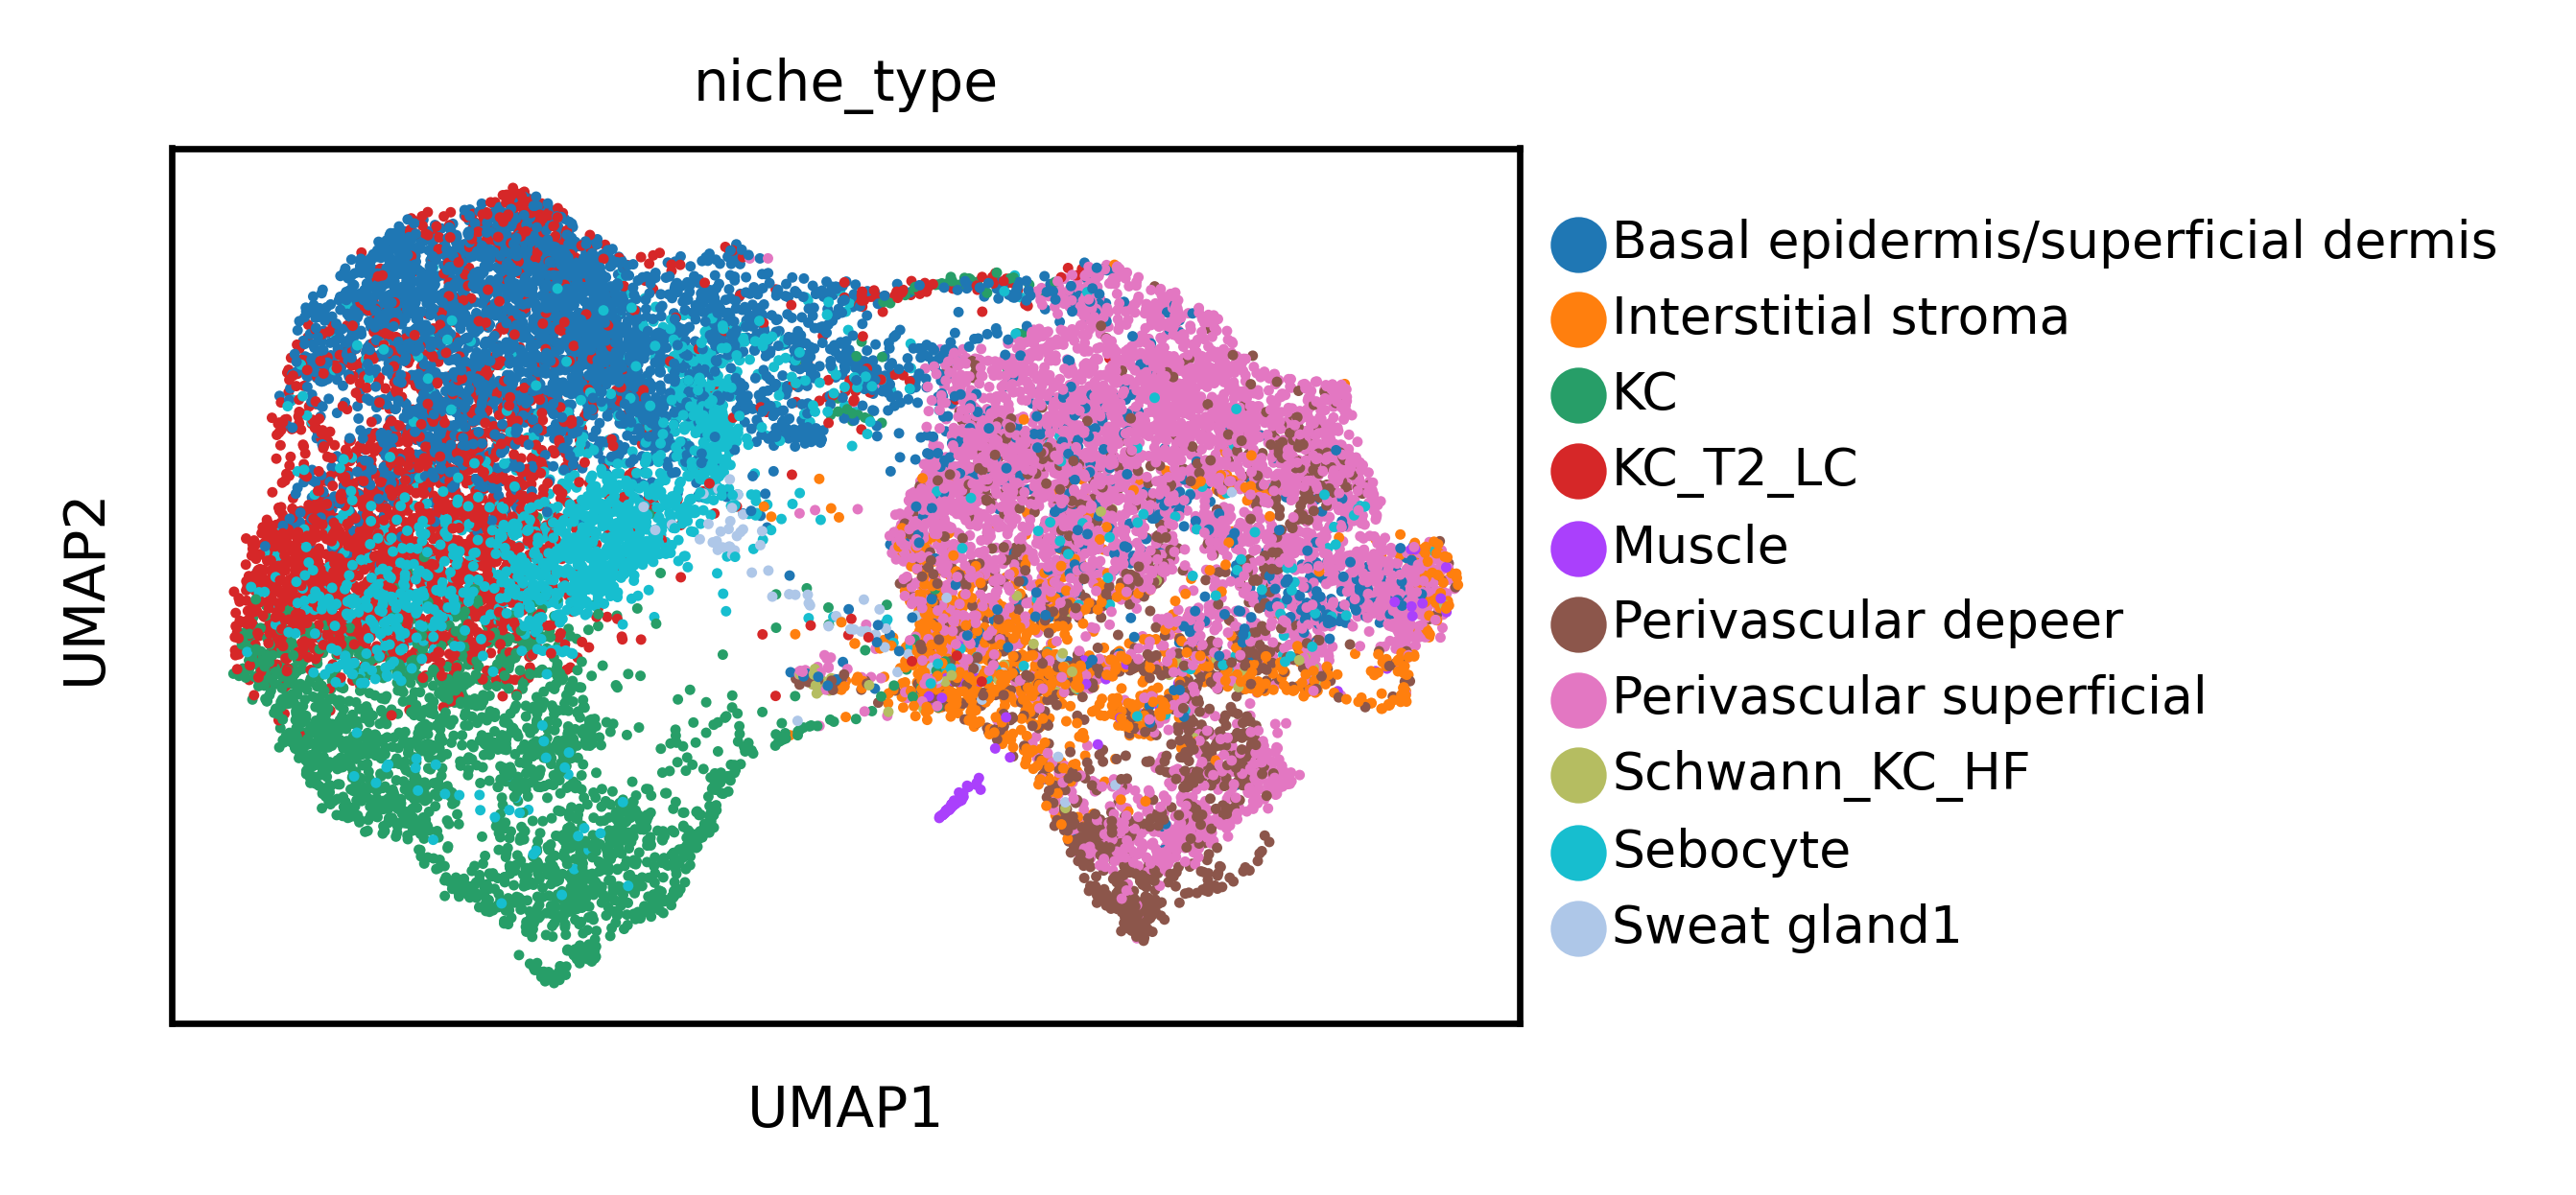

In [26]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')
# Store the neighborhood UMAP with a custom key
adata.obsm['neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')
# Store the cell UMAP with a custom key
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='cell',
           color=label)


#### 2.1.7 Niche Identification

In [59]:
# Set dataset params
batch_key = 'batch'
emb_key = 'cell'
latent_leiden_resolution = 0.3
spot_sizes = [0.3, 30]

latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'


In [60]:
# Compute UMAP representation for (aggregated) gene embeddings
if F'{emb_key}_connectivities' not in adata.obsp.keys():
    print("Computing sc.pp.neighbors...")
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'{emb_key}_emb_layer_{layer}',
                    key_added=emb_key)
if f'{emb_key}_umap' not in adata.obsm.keys():
    print("Computing sc.tl.umap...")
    sc.tl.umap(adata,
               neighbors_key=emb_key,
               key_added=f'{emb_key}_umap')


In [61]:
sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


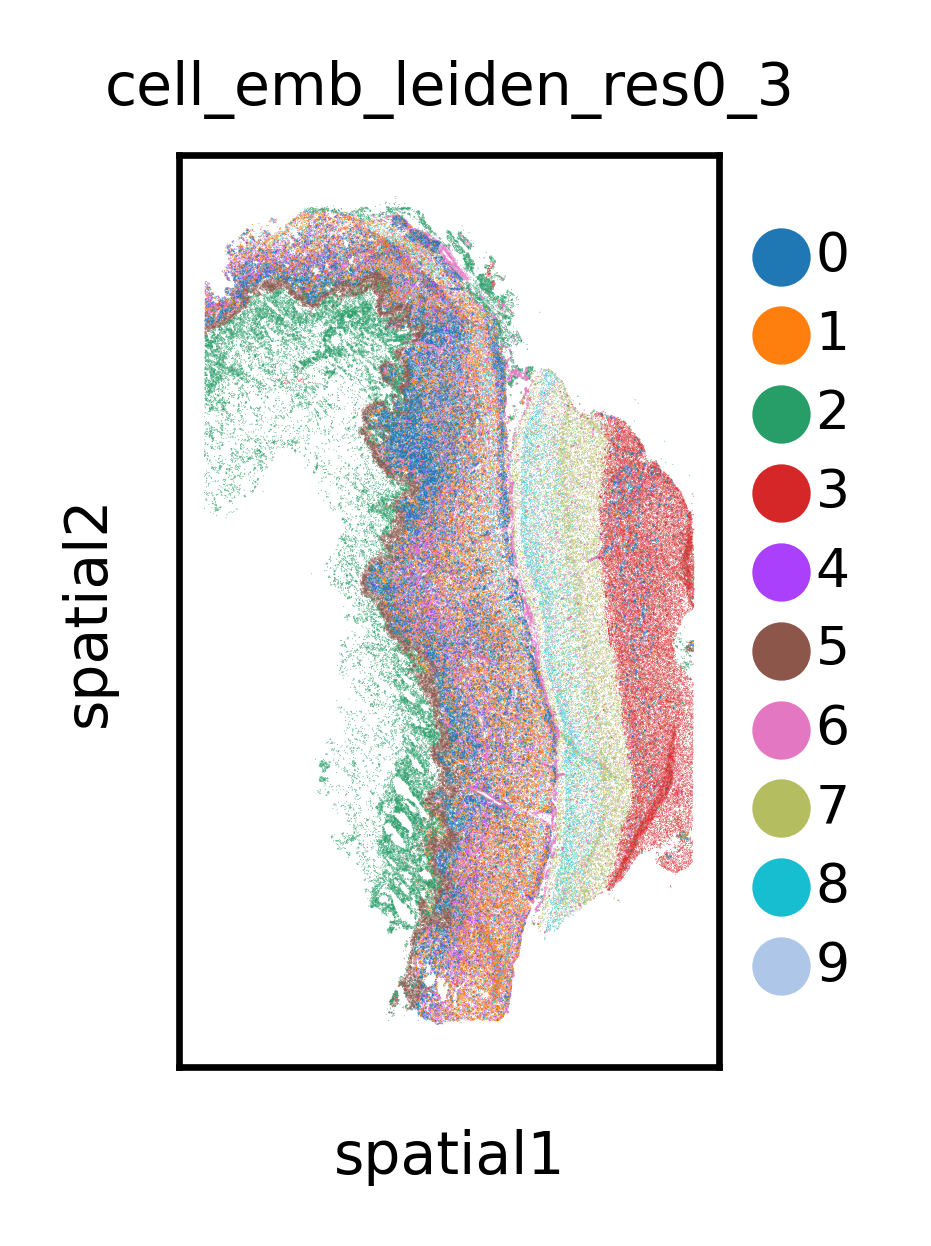

In [62]:
sc.pl.spatial(
    adata,
    color=latent_cluster_key,
    spot_size=spot_size,
    save=f'{dataset_name}_{latent_cluster_key}.svg'
)

#### get summery of gene_experesion on this data

In [78]:
def summarize_gene_expression(
    adata,
    subset_cell_ids: list,
    top_n: int = 10,
    ensembl_col: str = "ensembl_id"
):
    """
    Filter AnnData to a subset of cells, compute gene expression summaries,
    and return top expressed genes with Ensembl IDs.

    Args:
        adata (AnnData): Pre-loaded AnnData object.
        subset_cell_ids (list): List of cell IDs to filter.
        top_n (int): Number of top expressed genes to return.
        ensembl_col (str): Column in adata.var that contains Ensembl IDs.

    Returns:
        combined_counts (pd.DataFrame): Filtered cell-by-gene count matrix.
        top_gene_df (pd.DataFrame): DataFrame with top gene names and Ensembl IDs.
    """
    if 'cell_id' not in adata.obs.columns:
        raise KeyError("Expected `adata.obs` to contain a 'cell_id' column.")
    if ensembl_col not in adata.var.columns:
        raise KeyError(f"Expected `adata.var` to contain '{ensembl_col}' column.")

    # Filter to subset of cells
    mask = adata.obs['cell_id'].astype(str).isin(set(subset_cell_ids))
    filtered = adata[mask].copy()
    if filtered.n_obs == 0:
        raise ValueError("No matching cells found in the provided subset.")

    # Extract dense matrix
    matrix = filtered.X.toarray() if hasattr(filtered.X, "toarray") else filtered.X
    combined_counts = pd.DataFrame(matrix, columns=filtered.var_names, index=filtered.obs_names)

    # Compute mean expression and get top N genes
    mean_expr = combined_counts.mean(axis=0)
    top_genes = mean_expr.nlargest(top_n)

    # Map to Ensembl IDs
    var_df = adata.var.loc[top_genes.index]
    top_gene_df = pd.DataFrame({
        "gene_name": top_genes.index,
        "ensembl_id": var_df[ensembl_col].values,
        "mean_expression": top_genes.values
    })

    return combined_counts, top_gene_df


In [130]:
combined_counts, top_gene_df = summarize_gene_expression(adata, list(adata.obs['cell_id']),top_n=1000)

#### 2.1.8 compute_emd_distance
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [83]:
# each list should at least contain 20 gene each 
# to have score that is meaningful
# compute mmd also and add it 
cell_gene_ensembl_id = list(top_gene_df['ensembl_id'])
neighborhood_gene_ensembl_id = list(top_gene_df['ensembl_id'])  # ['all'] * len(perturbed_cell_id)


In [87]:
output_emd_distance = get_emd_distance( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: COMPUTE EMD DISTANCE BETWEEN GENE IN CELL AND NEIGHBORHOOD


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1441: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
136it [31:22, 13.84s/it]


In [88]:
adata.obs['emd_dist'] = output_emd_distance

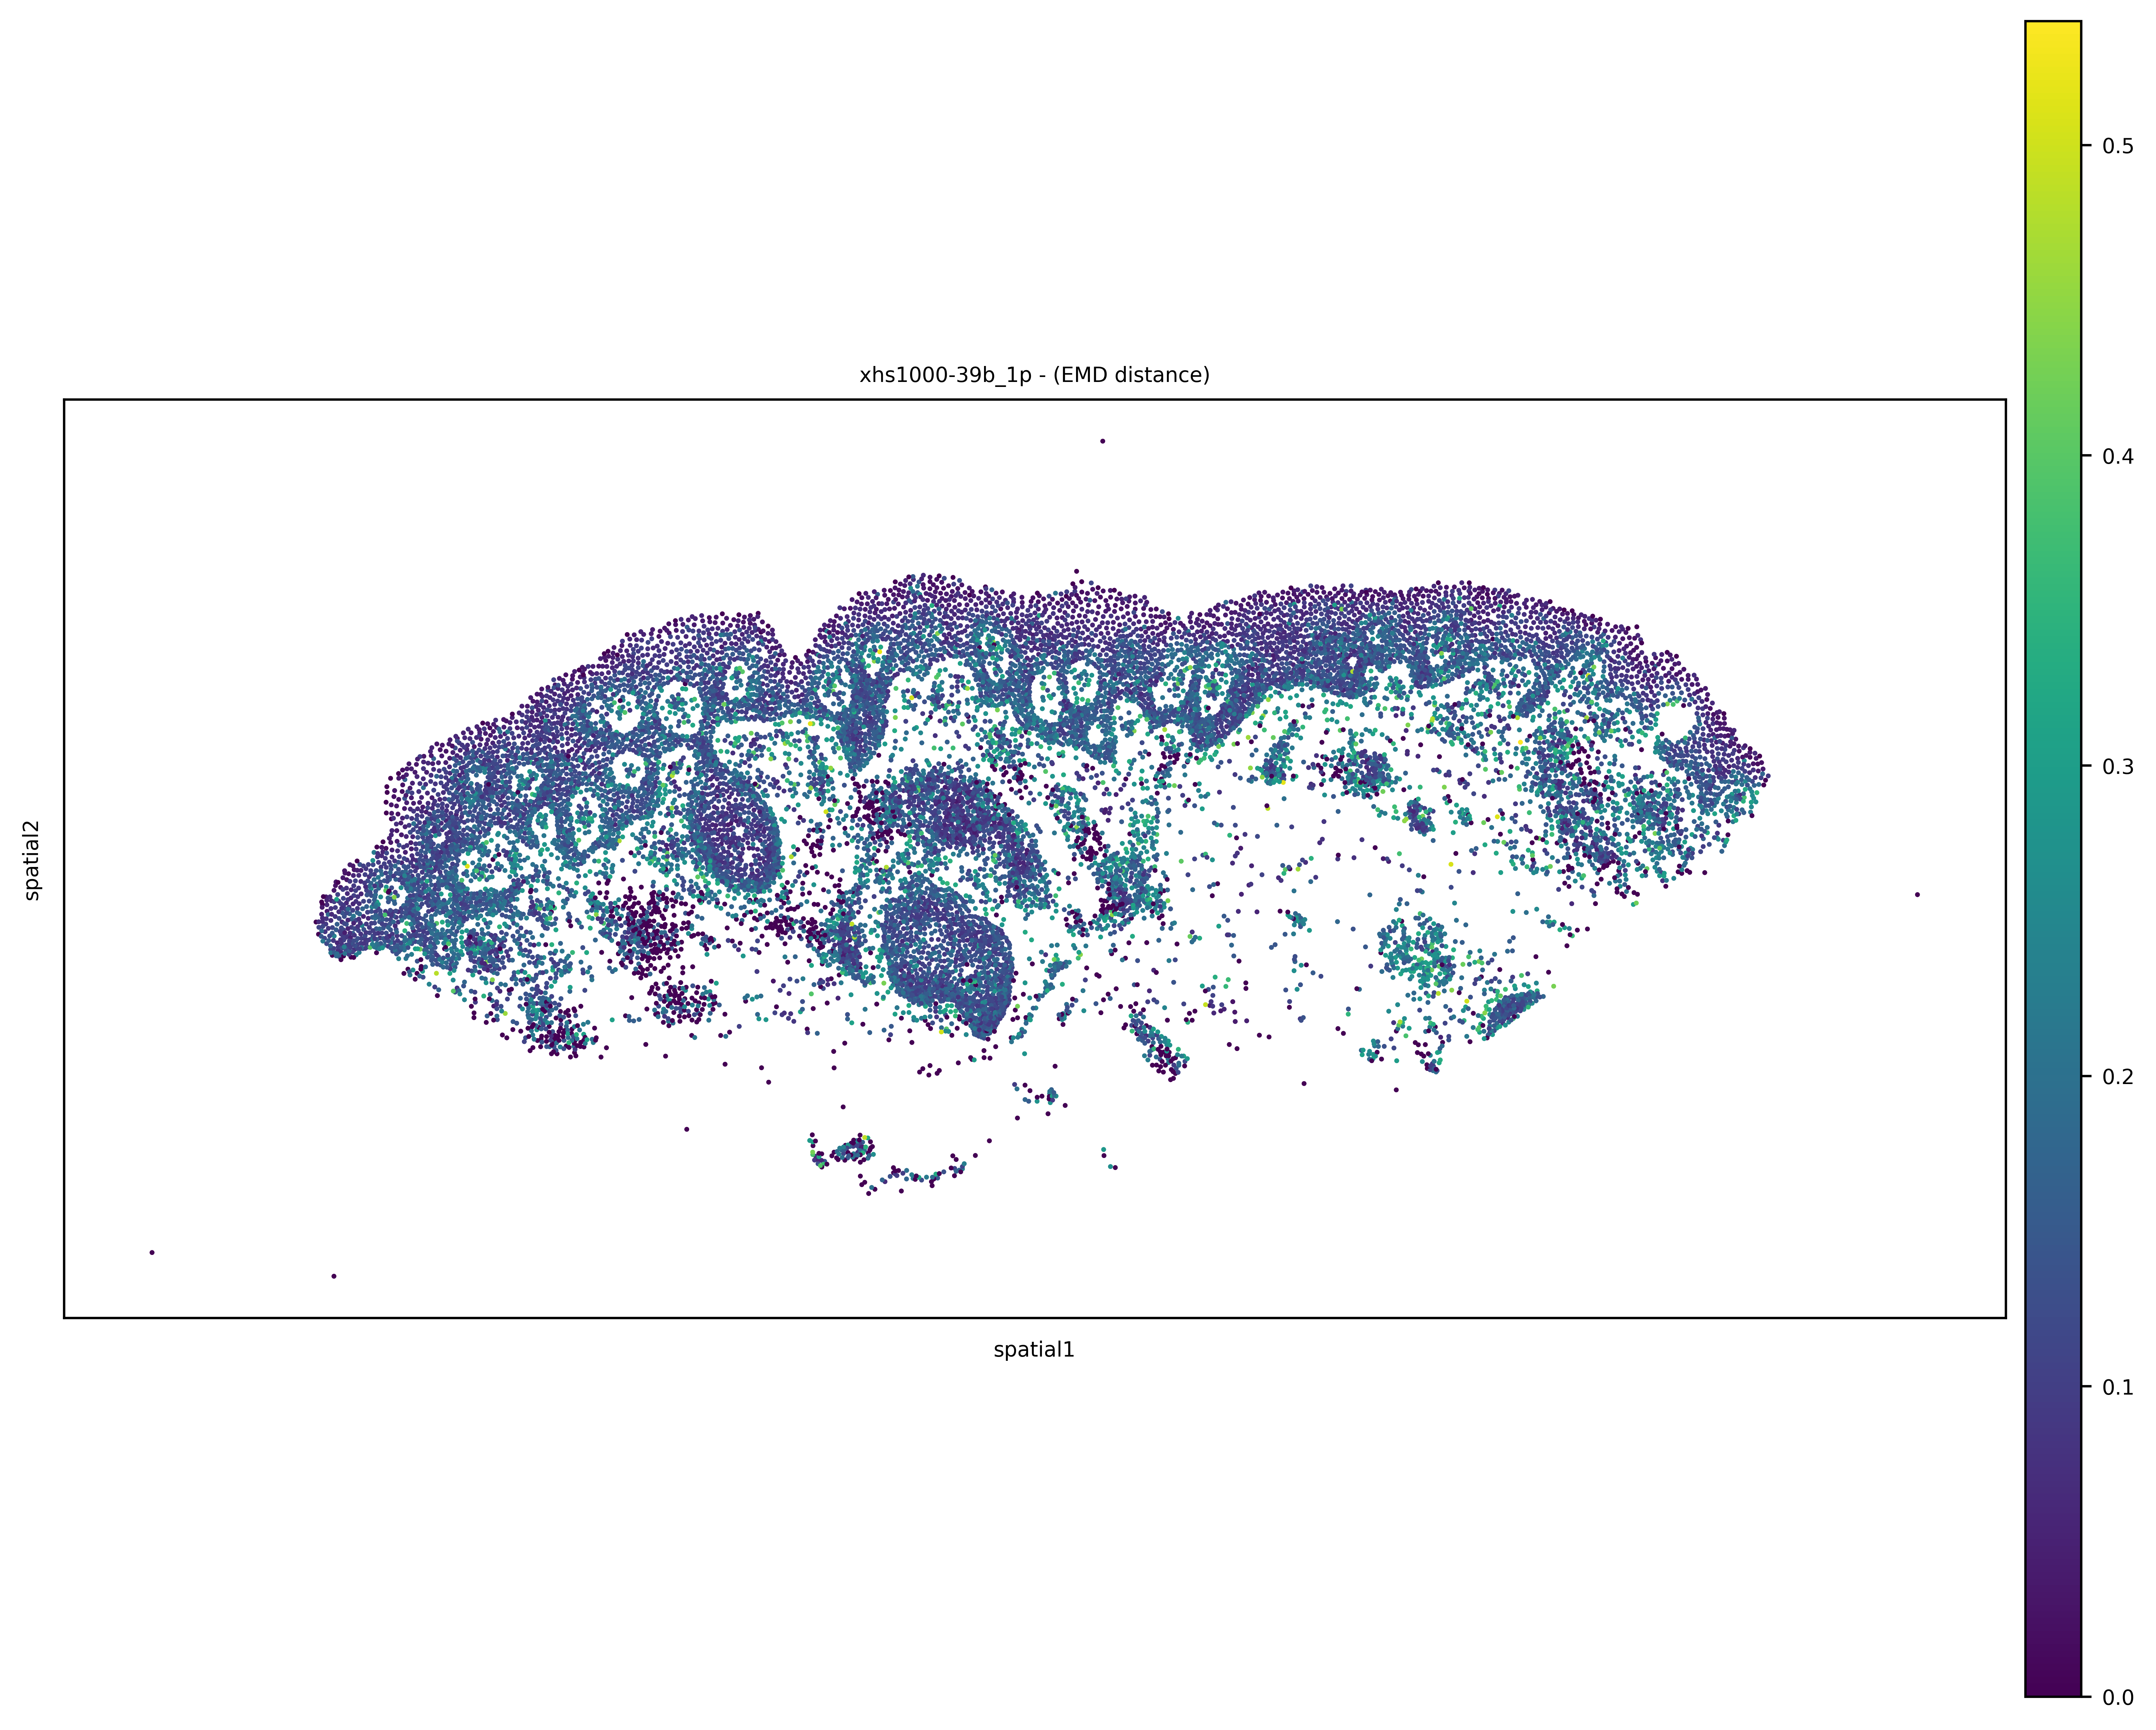

In [91]:
# 2) Normalize your data so that 0→0; 0.6→1.0
norm = Normalize(vmin=0.0, vmax=max(output_emd_distance))

# 3) Build the colormap
#cmap = make_thresholded_cmap(base_cmap="plasma", threshold=0.8)

sq.pl.spatial_scatter(
        adata,
        color='emd_dist',
        #cmap=cmap,
        norm=norm,
        shape=None,
        figsize=(10, 8),
        size=1.5,
        title=f"{dataset_name} - (EMD distance)",
)
plt.show()

#### 2.1.9 subset dataset instruction
You can use this method of subsetting dataasets in all your tasks. This is just a template for how to use it.

In [68]:
subset_cell_ids = ['1002_batch40_0',
 '1002_batch40_1',
 '1002_batch40_2',
 '1002_batch40_3',
 '1002_batch40_4',
 '1002_batch40_5',
 '1002_batch40_6',
 '1002_batch40_7',
 '1002_batch40_8',
 '1002_batch40_9']


In [75]:
dataset_subset = subset_by_cell_ids(dataset, subset_cell_ids)

Finding matching indices: 100%|█████████████████████████████████████████████| 321911/321911 [00:00<00:00, 5990020.70it/s]


In [78]:
dataset_subset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 10
})

#### 2.1.10 get_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [21]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12

In [22]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402']
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402'] # ['all'] * len(perturbed_cell_id)

In [ ]:
output_gene_embed = get_gene_embed( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [37]:
for gene_ens in output_gene_embed.keys():
    adata.obsm[gene_ens] = output_gene_embed[gene_ens]

#### 2.1.11 get_average_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
list(adata.var['ensembl_id'])

In [108]:
cell_gene_ensembl_id = list(top_gene_df['ensembl_id'])
neighborhood_gene_ensembl_id = list(top_gene_df['ensembl_id']) # ['all'] * len(perturbed_cell_id)

cell_gene_ensembl_id = list(adata.var['ensembl_id'])
neighborhood_gene_ensembl_id = list(adata.var['ensembl_id'])

In [109]:
output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1441: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
136it [39:20, 17.36s/it]
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1704: RuntimeWarning: invalid value encountered in divide
  cell_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1711: RuntimeWarning: invalid value encountered in divide
  neighborhood_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))


In [110]:
adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']

In [111]:
adata.uns['cell_gene_emb_average_per_data']

array([[ 0.5466791 ,  1.8663013 ,  2.4145224 , ...,  1.3252838 ,
        -0.77391136, -0.7527688 ],
       [-0.19709218, -0.02969043,  0.54059947, ...,  1.607284  ,
        -1.8314447 ,  0.18533859],
       [ 0.6949068 , -1.2387356 ,  0.4980921 , ...,  0.08149232,
        -1.8725107 ,  0.32196733],
       ...,
       [-0.11359677, -0.936968  ,  0.3405501 , ...,  1.0511014 ,
        -0.82951134, -0.29748303],
       [-0.27618885,  0.1361114 ,  0.07599593, ...,  0.500364  ,
        -1.2622386 ,  0.38157165],
       [ 0.09425392, -0.72793585,  0.36465788, ..., -0.23112081,
        -1.596888  , -0.21655516]], dtype=float32)

In [112]:
# 1) You can choose any of the embeddings, which could be either a cell or a neighborhood.
gene_emb_name = 'neighborhood_gene_emb_average_per_data'
gene_emb_name = 'cell_gene_emb_average_per_data'


In [113]:
gene_emb_name

'cell_gene_emb_average_per_data'

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


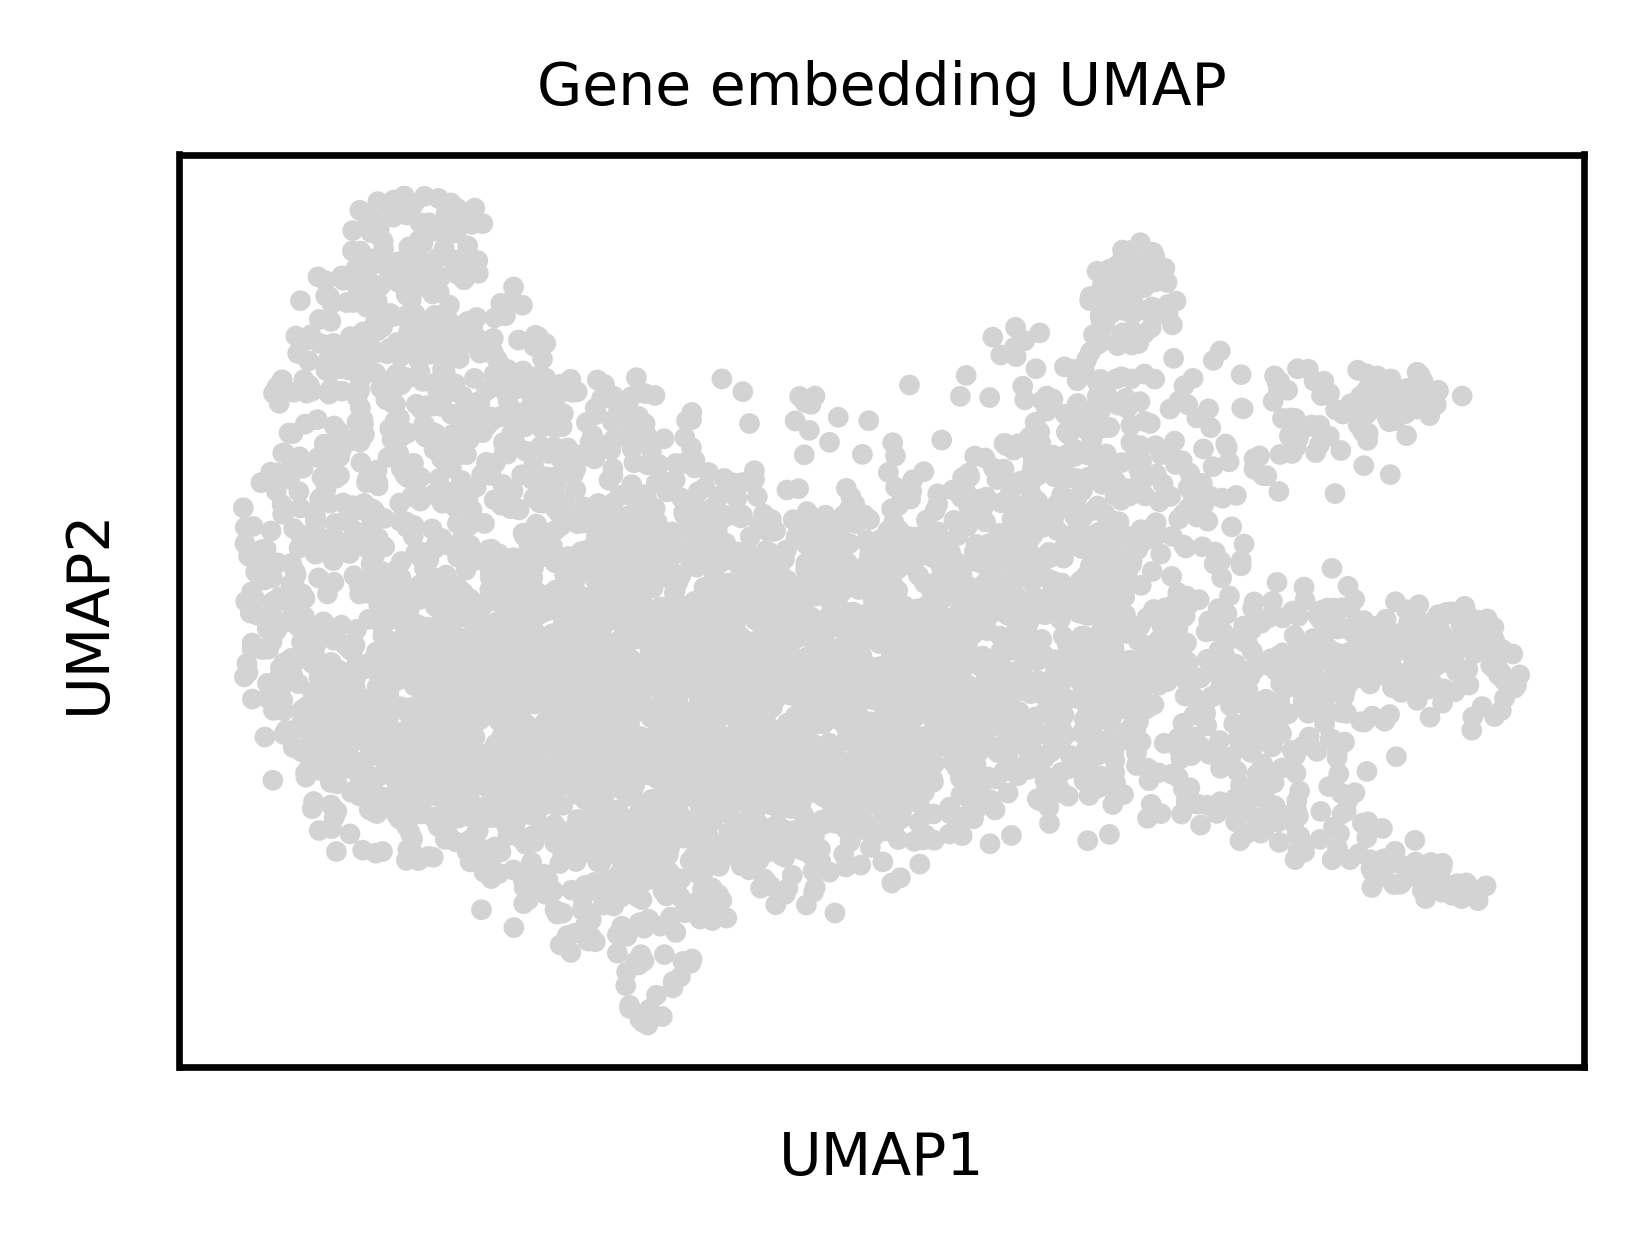

In [114]:
gene_emb = np.array(adata.uns[gene_emb_name])  # (n_genes, emb_dim)
gene_ids =  np.array(cell_gene_ensembl_id,  dtype=str)                  # (n_genes,)

# 2) Remove any gene rows containing NaNs
mask = ~np.isnan(gene_emb).any(axis=1)
gene_emb_clean = gene_emb[mask]
gene_ids_clean = gene_ids[mask]

# 3) Build a small AnnData where each "obs" is one gene
adata_genes = ad.AnnData(
    X=gene_emb_clean,
    obs=pd.DataFrame({'gene_id': gene_ids_clean})
)
adata_genes.obs_names = gene_ids_clean.astype(str)

# 4) Compute a neighborhood graph on the embeddings
sc.pp.neighbors(
    adata_genes,
    use_rep='X',
    n_neighbors=15,
    metric='euclidean'
)

# 5) Run UMAP
sc.tl.umap(
    adata_genes,
    #min_dist=0.5,
    #spread=1.0
)


# 7) (Optional) Quick plot
sc.pl.umap(
    adata_genes,
    title='Gene embedding UMAP',
    show=True
)


/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


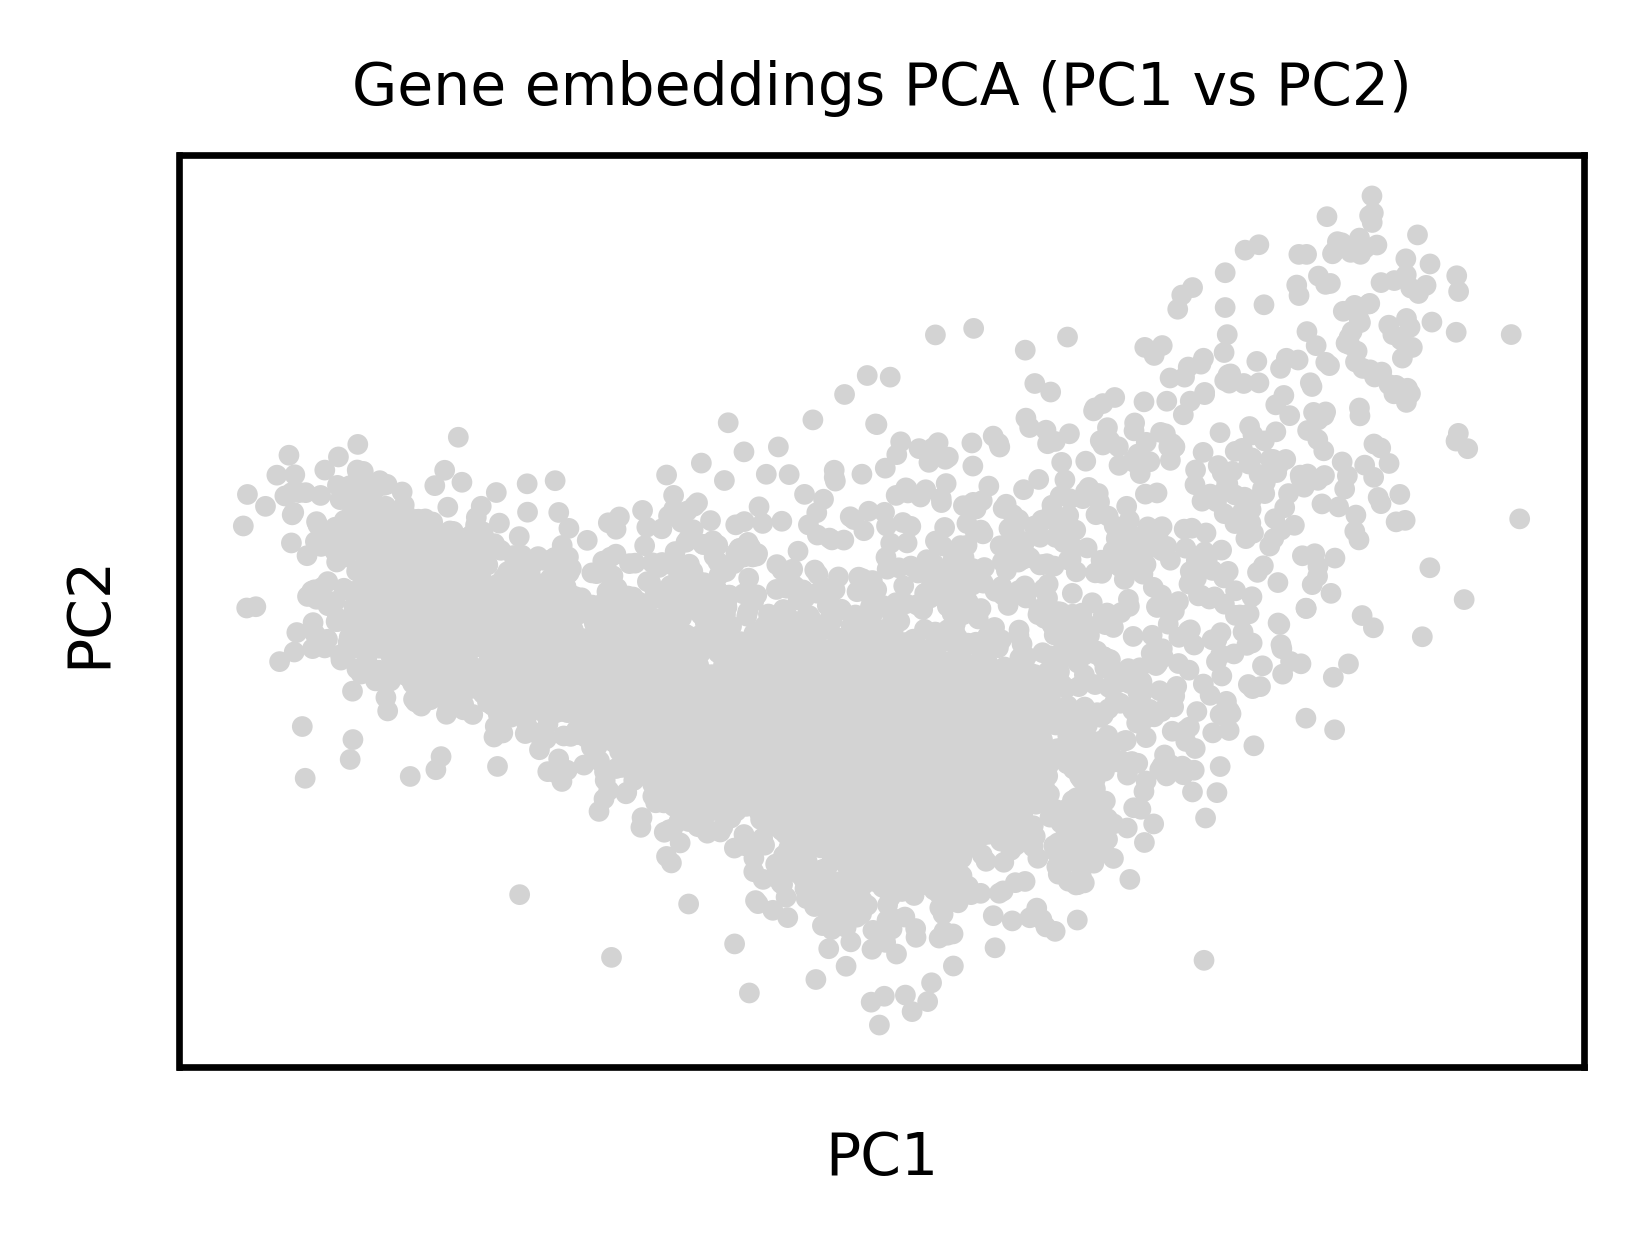

In [115]:
sc.tl.pca(adata_genes, n_comps=2, use_highly_variable=False, svd_solver='arpack')

sc.pl.pca(
    adata_genes,
    components=['1,2'],   # plot PC1 vs PC2
    color=None,
    title='Gene embeddings PCA (PC1 vs PC2)',
    show=True
)


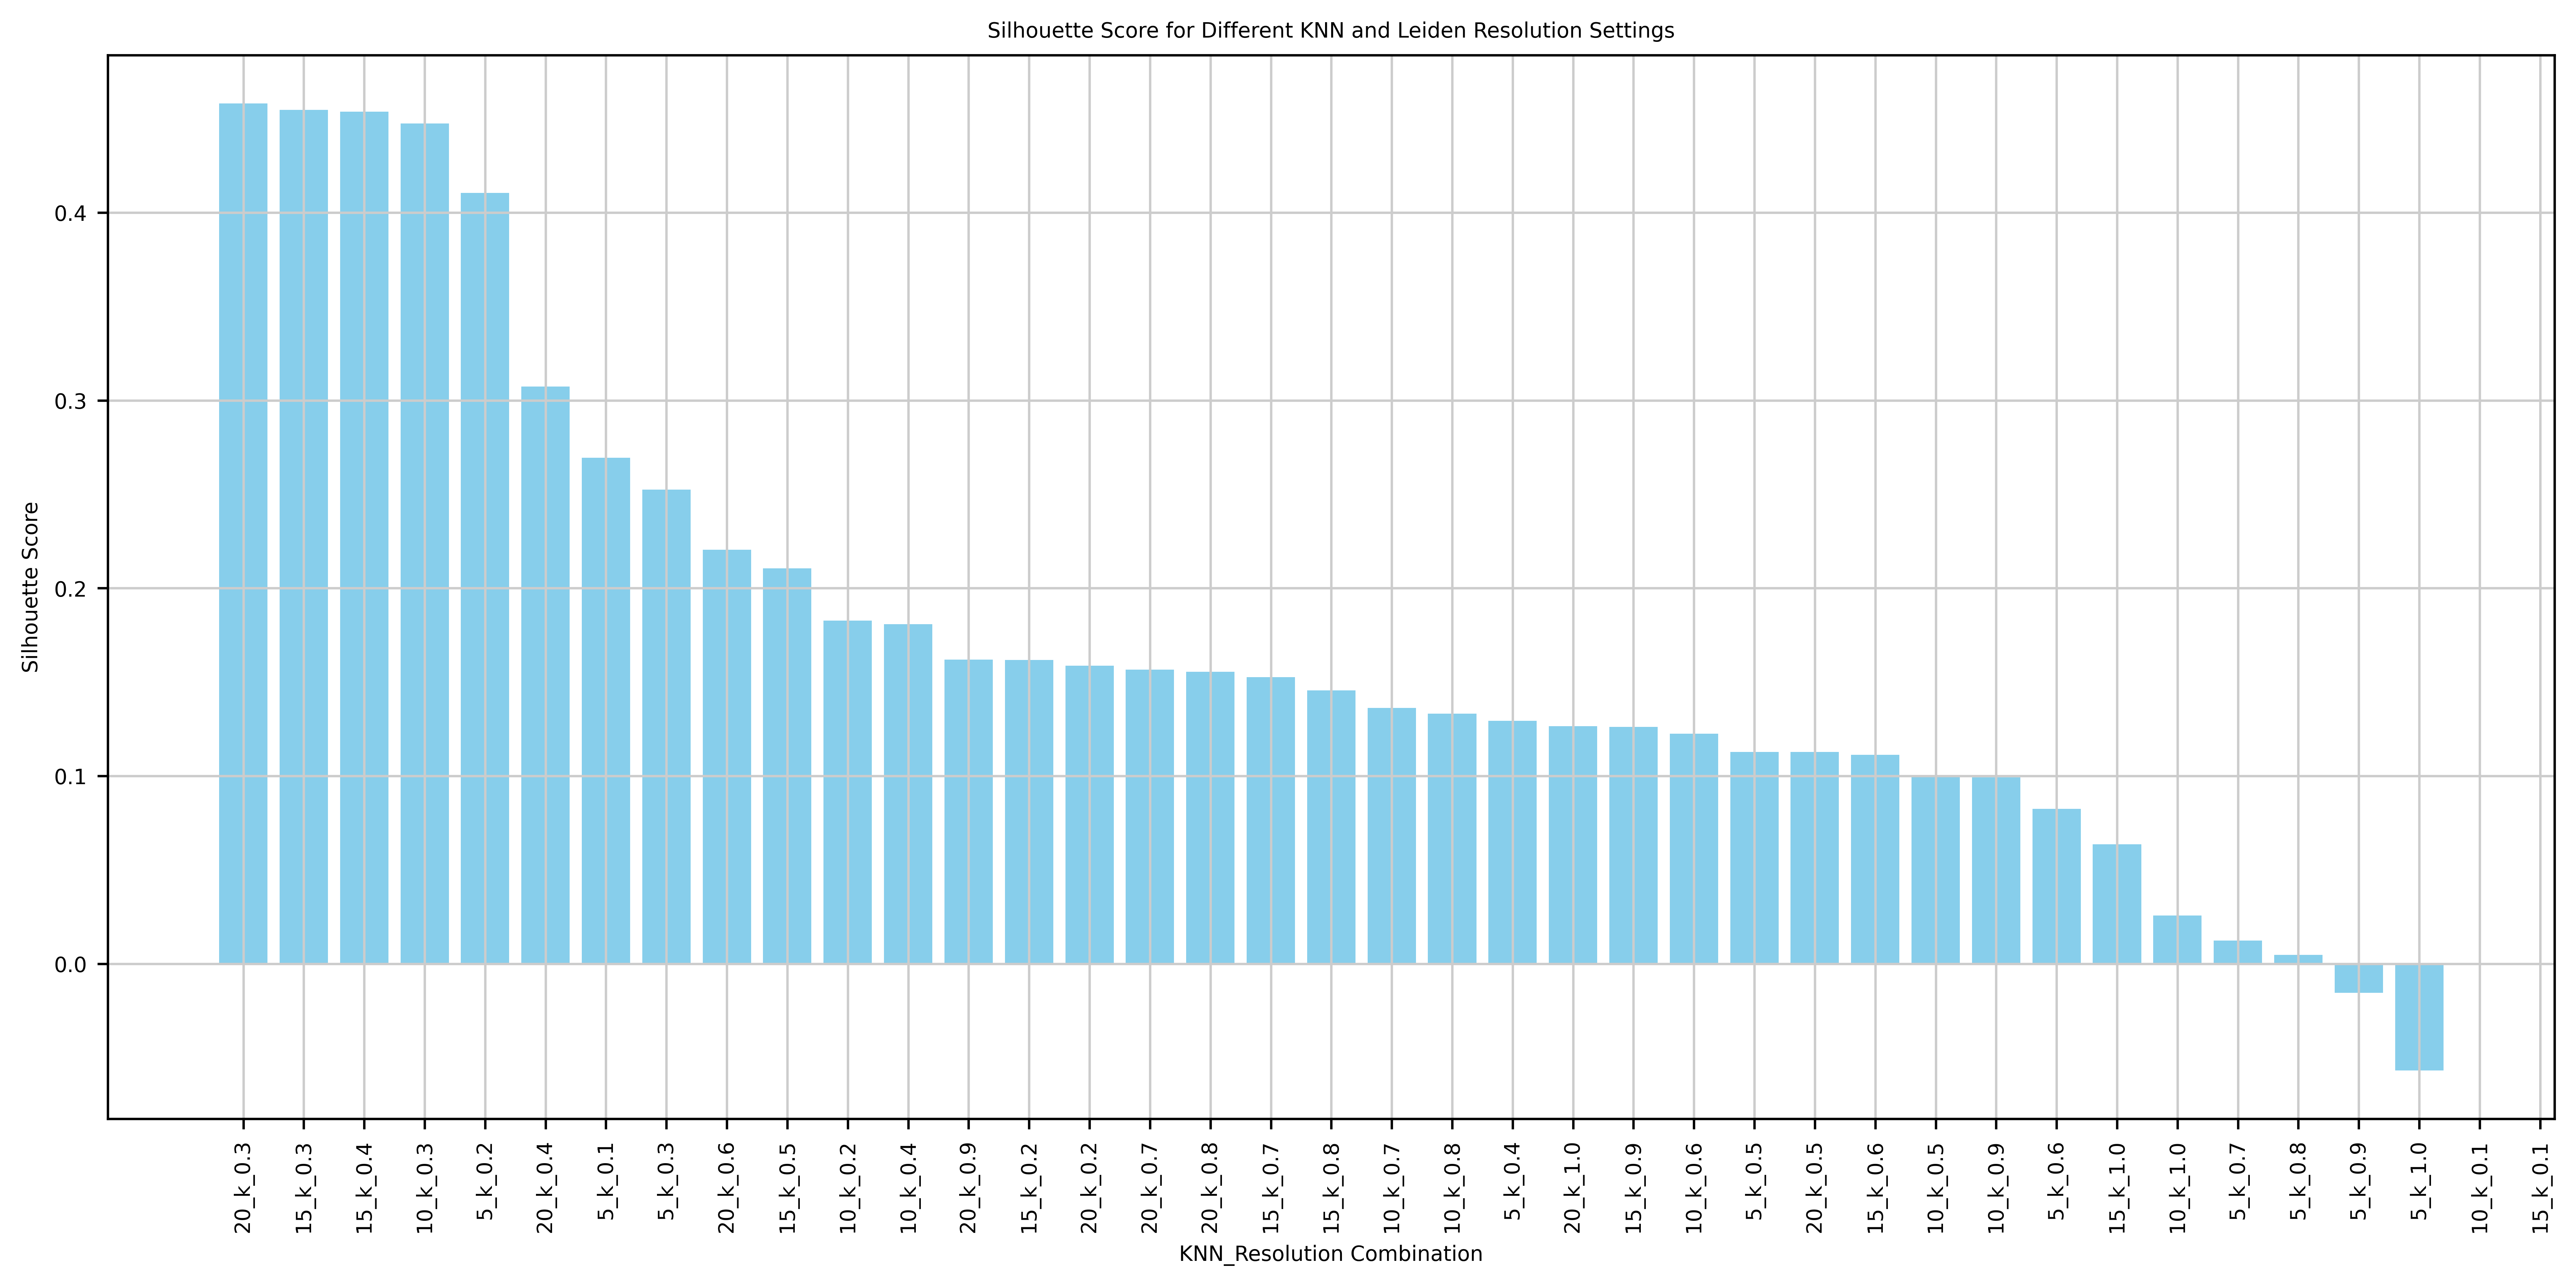

In [116]:
# Store results here
results = []

# Define parameters
knn_values = [5, 10, 15, 20]
resolutions = np.arange(0.1, 1.1, 0.1)  # 0.1 to 1.0

# Loop over each KNN and resolution combination
for knn in knn_values:
    sc.pp.neighbors(adata_genes, n_neighbors=knn, use_rep='X')  # use 'X' or other embedding like 'X_pca'
    
    for res in resolutions:
        # Run Leiden clustering
        sc.tl.leiden(adata_genes, resolution=res, key_added='leiden_tmp')
        
        # Compute silhouette score
        labels = adata_genes.obs['leiden_tmp']
        if len(np.unique(labels)) < 2:
            score = np.nan  # silhouette score not defined for 1 cluster
        else:
            score = silhouette_score(adata_genes.obsm['X_pca'], labels)  # you can change to 'X' if no PCA
        
        # Store results
        results.append({
            'knn': knn,
            'resolution': round(res, 2),
            'silhouette_score': score
        })

# Convert results to DataFrame
df = pd.DataFrame(results)
df['combo'] = df['knn'].astype(str) + '_k_' + df['resolution'].astype(str)

# Plot
plt.figure(figsize=(12, 6))
df_sorted = df.sort_values('silhouette_score', ascending=False)
plt.bar(df_sorted['combo'], df_sorted['silhouette_score'], color='skyblue')
plt.xticks(rotation=90)
plt.ylabel("Silhouette Score")
plt.xlabel("KNN_Resolution Combination")
plt.title("Silhouette Score for Different KNN and Leiden Resolution Settings")
plt.tight_layout()
plt.show()


In [117]:
sc.pp.neighbors(adata_genes,n_neighbors=20)
sc.tl.leiden(adata_genes,resolution=0.3,key_added='r9')

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


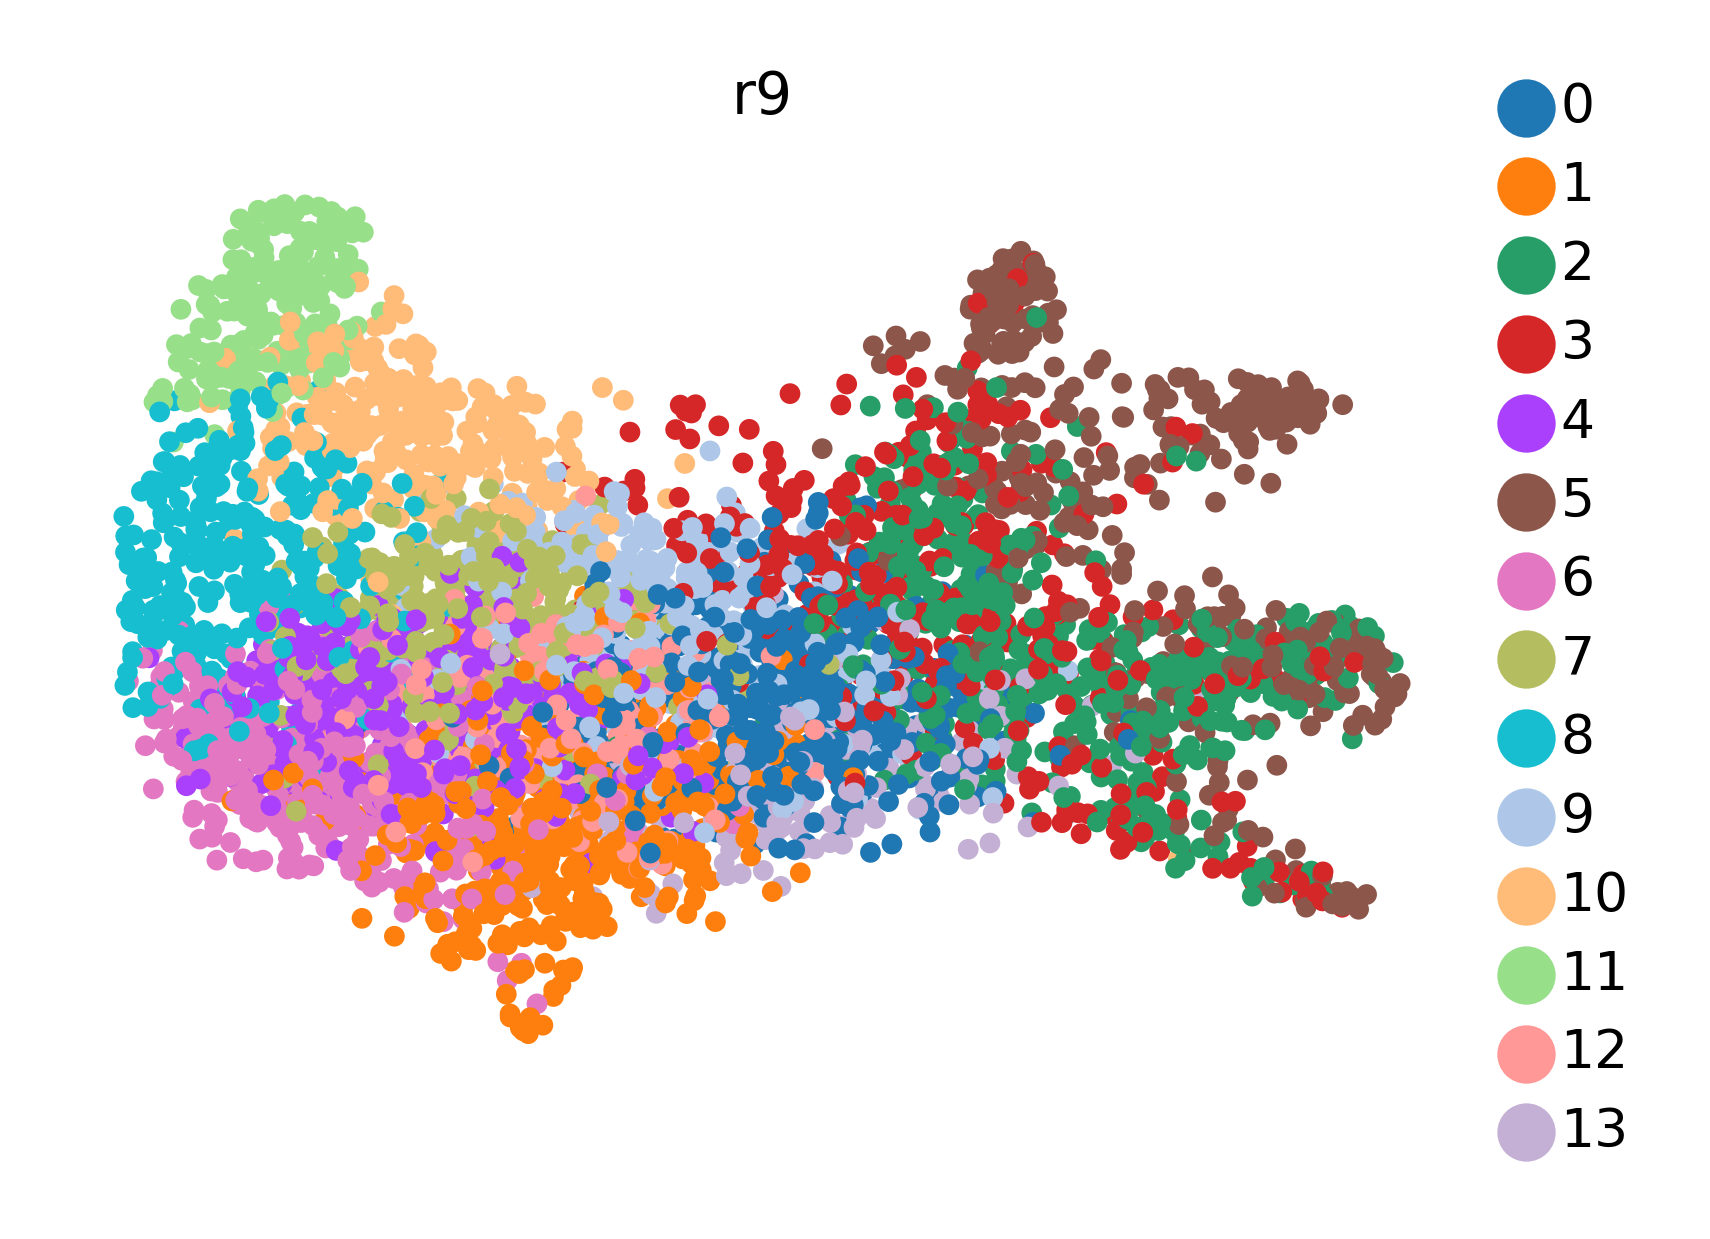

In [118]:
sc.pl.umap(adata_genes,color='r9',frameon=False)

In [119]:
id_to_name = {ensg: name for name, ensg in adata.var['ensembl_id'].items()}

In [124]:
interesting_group = '10'
ens_interesting_group = list(adata_genes.obs[adata_genes.obs['r9']==interesting_group]['gene_id'])

In [125]:
genes  = [ id_to_name.get(ensg, "UNKNOWN") for ensg in ens_interesting_group]

In [126]:
len(genes)

262

In [127]:
# 2) Your input gene list
# 3) Call gseapy.enrichr
#    You can choose any Enrichr library; here are some examples:
# I should create a mapping from gene_id to ens
# from 110 release
libraries = [
    'KEGG_2019_Human',
    'GO_Biological_Process_2021',
    'Reactome_Pathways_2024',
    'MSigDB_Hallmark_2020'
]

# Run ORA for each library
results = {}
for lib in libraries:
    enr = gp.enrichr(
        gene_list = genes,
        gene_sets  = lib,
        outdir     = None,        # don't write files
        cutoff     = 0.05,         # only show terms with adjusted p < 0.05
    )
    # enr.results is a pandas DataFrame
    results[lib] = enr.results

# 4) Inspect top enriched terms for each library
for lib, df in results.items():
    print(f"\n=== Top 5 terms in {lib} ===")
    display(df[['Term','Adjusted P-value','Combined Score']].head(20))



=== Top 5 terms in KEGG_2019_Human ===


,Term,Adjusted P-value,Combined Score
0,Neuroactive ligand-receptor interaction,9.565594e-11,194.927911
1,cAMP signaling pathway,4.982414e-04,62.838609
2,Calcium signaling pathway,5.144602e-04,63.065510
3,Regulation of lipolysis in adipocytes,4.241982e-03,88.746828
4,Ferroptosis,7.626055e-02,53.550656
5,PPAR signaling pathway,9.427507e-02,32.468850
6,Transcriptional misregulation in cancer,9.427507e-02,19.864850
7,Cholinergic synapse,9.427507e-02,24.435261
8,Salivary secretion,1.513277e-01,22.578230
9,Regulation of actin cytoskeleton,1.513277e-01,14.655651



=== Top 5 terms in GO_Biological_Process_2021 ===


,Term,Adjusted P-value,Combined Score
0,negative regulation of inflammatory response t...,0.000184,115.760126
1,regulation of inflammatory response to antigen...,0.000184,114.224924
2,positive regulation of cell population prolife...,0.000184,58.426843
3,adenylate cyclase-activating G protein-coupled...,0.000184,117.696671
4,positive regulation of ERK1 and ERK2 cascade (...,0.000184,93.878754
5,negative regulation of immune response (GO:005...,0.000227,88.007961
6,negative regulation of inflammatory response (...,0.000245,77.897989
7,positive regulation of calcium ion transmembra...,0.000284,301.498607
8,"G protein-coupled receptor signaling pathway, ...",0.000464,142.365516
9,regulation of ERK1 and ERK2 cascade (GO:0070372),0.000614,62.044270



=== Top 5 terms in Reactome_Pathways_2024 ===


,Term,Adjusted P-value,Combined Score
0,GPCR Ligand Binding,4.662202e-10,159.679352
1,Signaling by GPCR,1.425985e-08,99.683611
2,GPCR Downstream Signalling,1.425985e-08,103.841472
3,Amine Ligand-Binding Receptors,2.658037e-08,533.834531
4,Class A 1 (Rhodopsin-like Receptors),7.435449e-08,121.835521
5,G Alpha (S) Signalling Events,8.396975e-04,68.703425
6,Serotonin Receptors,1.212303e-03,429.841359
7,G Alpha (I) Signalling Events,2.344798e-02,27.278701
8,Signal Transduction,2.908706e-02,13.616099
9,Nuclear Receptor Transcription Pathway,3.824845e-02,58.717454



=== Top 5 terms in MSigDB_Hallmark_2020 ===


,Term,Adjusted P-value,Combined Score
0,Inflammatory Response,0.000591,55.879265
1,Spermatogenesis,0.043863,26.052395
2,TNF-alpha Signaling via NF-kB,0.053477,17.004677
3,Xenobiotic Metabolism,0.053477,17.004677
4,IL-2/STAT5 Signaling,0.118650,11.529853
5,KRAS Signaling Up,0.118650,11.400616
6,Estrogen Response Early,0.208377,7.147241
7,Estrogen Response Late,0.208377,7.147241
8,Complement,0.208377,7.147241
9,p53 Pathway,0.208377,7.147241


#### 2.1.12 compute_spatial_score
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [29]:
adata.var

,ensembl_id
gene_name,
A2ML1,ENSG00000166535
AAMP,ENSG00000127837
AAR2,ENSG00000131043
AARSD1,ENSG00000266967
ABAT,ENSG00000183044
...,...
ZSCAN26,ENSG00000197062
ZSWIM6,ENSG00000130449
ZUP1,ENSG00000153975


In [92]:
# for out put of get_top_gene_score be correct both cell_gene_ensembl_id and 
# neighborhood_gene_ensembl_id should have same size and same order
cell_gene_ensembl_id =  list(top_gene_df['ensembl_id']) 
neighborhood_gene_ensembl_id =  list(top_gene_df['ensembl_id'])  # ['all'] * len(perturbed_cell_id)

In [94]:
output_cosine_sim_score = get_spatial_score(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: COMPUTE THE COSINE SIMILARITY SCORE BETWEEN GENES IN THE CELL AND GENES IN THE NEIGHBORHOOD.


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


136it [22:04,  9.74s/it]


In [95]:
gene_pair_score = output_cosine_sim_score['cos_sim_neighborhood'] / output_cosine_sim_score['cos_sim_cell']

In [96]:
gene_pair_score

array([[0.79554874, 0.7319543 , 0.75526434, ..., 0.7530944 , 0.7303996 ,
        0.8029102 ],
       [0.74705005, 0.83884805, 0.76450133, ..., 0.76536685, 0.75351495,
        0.8000488 ],
       [0.7456478 , 0.7602877 , 0.8106688 , ..., 0.7263614 , 0.7212411 ,
        0.79065126],
       ...,
       [0.81182975, 0.8310208 , 0.8085602 , ..., 0.8407357 , 0.7860664 ,
        0.84889746],
       [0.8094414 , 0.792606  , 0.79485065, ..., 0.7976192 , 0.82496464,
        0.84295344],
       [0.8362466 , 0.83188725, 0.8253627 , ..., 0.82107294, 0.80348814,
        0.86603564]], dtype=float32)

In [97]:
output_cosine_sim_score['cell_count_neighborhood']

array([[13681., 13652., 13572., ...,  6224.,  7150.,  6087.],
       [13242., 13219., 13186., ...,  6009.,  7186.,  5705.],
       [12276., 12270., 12249., ...,  5395.,  6701.,  5015.],
       ...,
       [ 1027.,  1028.,  1027., ...,   590.,   483.,   556.],
       [ 1371.,  1369.,  1367., ...,   584.,   973.,   551.],
       [  994.,   993.,   993., ...,   594.,   477.,   606.]],
      dtype=float32)

In [105]:
df_gene_scores = get_top_gene_score(gene_pair_score, 
                                    cell_gene_ensembl_id, 
                                    gene_df=adata.var, 
                                    gene_counts= output_cosine_sim_score['cell_count_neighborhood'],
                                    min_count = 20)

In [107]:
df_gene_scores.sort_values(by='gene_score', ascending=False)

,gene_ensembl,gene_name,gene_score
386,ENSG00000198851,CD3E,0.902163
855,ENSG00000129451,KLK10,0.900474
820,ENSG00000100170,SLC5A1,0.898774
747,ENSG00000119912,IDE,0.898454
623,ENSG00000171476,HOPX,0.897593
...,...,...,...
298,ENSG00000164111,ANXA5,0.740825
514,ENSG00000138385,SSB,0.739267
815,ENSG00000085063,CD59,0.733497
780,ENSG00000196628,TCF4,0.733060


In [102]:
df_gene_pairs_score = get_top_gene_pairs(
    torch.from_numpy(gene_pair_score),
    count_cell=torch.from_numpy(output_cosine_sim_score['cell_count_neighborhood']),
    count_neb=torch.from_numpy(output_cosine_sim_score['cell_count_cell']),
    cos_sim_cell=torch.from_numpy(output_cosine_sim_score['cell_count_cell']),
    cos_sim_neb=torch.from_numpy(output_cosine_sim_score['cos_sim_neighborhood']),
    gene_df=adata.var,
    cell_gene_ids=cell_gene_ensembl_id,
    neighborhood_gene_ids=neighborhood_gene_ensembl_id,
    min_count=20,
    sim_thresh=0.0,
    k=500
)


In [103]:
df_gene_pairs_score

,row_idx,col_idx,cell_ensembl,neb_ensembl,cell_gene_name,neb_gene_name,gene_pair_score
0,972,973,ENSG00000101109,ENSG00000203786,STK4,KPRP,1.047310
1,817,973,ENSG00000089159,ENSG00000203786,PXN,KPRP,1.034731
2,823,189,ENSG00000132155,ENSG00000204539,RAF1,CDSN,1.016811
3,534,189,ENSG00000141510,ENSG00000204539,TP53,CDSN,1.015863
4,775,189,ENSG00000118217,ENSG00000204539,ATF6,CDSN,1.006099
...,...,...,...,...,...,...,...
495,806,624,ENSG00000141527,ENSG00000206075,CARD14,SERPINB5,0.936308
496,467,973,ENSG00000186716,ENSG00000203786,BCR,KPRP,0.936305
497,317,973,ENSG00000070770,ENSG00000203786,CSNK2A2,KPRP,0.936298
498,184,189,ENSG00000104549,ENSG00000204539,SQLE,CDSN,0.936280


#### 2.1.13 Perturbed Data

In [ ]:
# Define perturbations
perturbed_cell_id = ['1007_batch20_0', '1007_batch20_0', '1007_batch20_1']
perturbed_ensembl_id = ['all', 'all', 'ENSG00000169194'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'foldchange'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, 0.5] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

In [ ]:
perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path)

#### 2.1.14 Embed Perturb Data

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)